In [22]:
!pip install -q kagglehub
import kagglehub, glob, os
import pandas as pd
import numpy as np

path = kagglehub.dataset_download("shivamb/machine-predictive-maintenance-classification")
csvs = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
print("Fichiers :", csvs)

df = pd.read_csv(csvs[0])

print("\nShape :", df.shape)
print(df.head())
print("\n", df.info())
print("\n", df.describe().T)

print("\nValeurs manquantes :\n", df.isnull().sum())
print("Doublons :", df.duplicated().sum())
print("UDI uniques :", df["UDI"].nunique(), "| Product ID uniques :", df["Product ID"].nunique())

print("\nRépartition de Failure Type :")
print(df["Failure Type"].value_counts())
print((df["Failure Type"].value_counts(normalize=True) * 100).round(2))

print("\nRépartition de Type (qualité L/M/H) :")
print(df["Type"].value_counts())

print("\nCohérence Target vs Failure Type :")
print(pd.crosstab(df["Target"], df["Failure Type"]))

100%|██████████| 137k/137k [00:00<00:00, 15.2MB/s]

Extracting files...
Fichiers : ['/root/.cache/kagglehub/datasets/shivamb/machine-predictive-maintenance-classification/versions/1/predictive_maintenance.csv']

Shape : (10000, 10)
   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Target Failure Type  
0                    1551         42.8                0       0   No Failure  
1                    1408         46.3                3       0   No Failure  
2                    1498         49.4                5       0   No Failure  
3                    1433         39.5                7       0   No Fa


                            count        mean          std     min      25%  \
UDI                      10000.0  5000.50000  2886.895680     1.0  2500.75   
Air temperature [K]      10000.0   300.00493     2.000259   295.3   298.30   
Process temperature [K]  10000.0   310.00556     1.483734   305.7   308.80   
Rotational speed [rpm]   10000.0  1538.77610   179.284096  1168.0  1423.00   
Torque [Nm]              10000.0    39.98691     9.968934     3.8    33.20   
Tool wear [min]          10000.0   107.95100    63.654147     0.0    53.00   
Target                   10000.0     0.03390     0.180981     0.0     0.00   

                            50%      75%      max  
UDI                      5000.5  7500.25  10000.0  
Air temperature [K]       300.1   301.50    304.5  
Process temperature [K]   310.1   311.10    313.8  
Rotational speed [rpm]   1503.0  1612.00   2886.0  
Torque [Nm]                40.1    46.80     76.6  
Tool wear [min]           108.0   162.00    253.0  
Target   

In [23]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, os
os.makedirs("images", exist_ok=True)
sns.set_style("whitegrid")

df = pd.read_csv(csvs[0])

# 1) Lignes contradictoires : Target = 1 mais "No Failure"
bad = (df["Target"] == 1) & (df["Failure Type"] == "No Failure")
print("Lignes contradictoires supprimées :", bad.sum())
df = df[~bad].reset_index(drop=True)

# 2) Identifiants + Target (fuite de la cible)
df = df.drop(columns=["UDI", "Product ID", "Target"])

# 3) Noms simples
df = df.rename(columns={"Air temperature [K]": "air_temp", "Process temperature [K]": "proc_temp",
                        "Rotational speed [rpm]": "rpm", "Torque [Nm]": "torque",
                        "Tool wear [min]": "tool_wear"})

# 4) Encodage de Type (ordinal) et de la cible
df["Type"] = df["Type"].map({"L": 0, "M": 1, "H": 2})
classes = ["No Failure", "Heat Dissipation Failure", "Power Failure",
           "Overstrain Failure", "Tool Wear Failure", "Random Failures"]
df["y"] = df["Failure Type"].map({c: i for i, c in enumerate(classes)})

# 5) Variables construites (relations physiques)
df["temp_diff"] = df["proc_temp"] - df["air_temp"]
df["power_w"] = df["torque"] * df["rpm"] * 2 * np.pi / 60
df["wear_torque"] = df["tool_wear"] * df["torque"]

num_cols = ["air_temp", "proc_temp", "rpm", "torque", "tool_wear", "temp_diff", "power_w", "wear_torque"]
features = ["Type"] + num_cols

# 6) Outliers (IQR) : on les garde, ce sont des régimes de fonctionnement réels
for c in ["air_temp", "proc_temp", "rpm", "torque", "tool_wear"]:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    print(f"Outliers {c:<10}: {n_out}")

print("\nShape finale :", df.shape, "| NaN :", df.isnull().sum().sum())
print(df["Failure Type"].value_counts())
print(df[features].describe().T.round(2))

Lignes contradictoires supprimées : 9
Outliers air_temp  : 0
Outliers proc_temp : 0
Outliers rpm       : 418
Outliers torque    : 70
Outliers tool_wear : 0

Shape finale : (9991, 11) | NaN : 0
Failure Type
No Failure                  9643
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64
              count     mean      std      min      25%      50%      75%  \
Type         9991.0     0.50     0.67     0.00     0.00     0.00     1.00   
air_temp     9991.0   300.00     2.00   295.30   298.30   300.10   301.50   
proc_temp    9991.0   310.01     1.48   305.70   308.80   310.10   311.10   
rpm          9991.0  1538.80   179.32  1168.00  1423.00  1503.00  1612.00   
torque       9991.0    39.99     9.97     3.80    33.20    40.10    46.70   
tool_wear    9991.0   107.94    63.66     0.00    53.00   108.00   162.00   
temp_diff    9991.0    10.00   

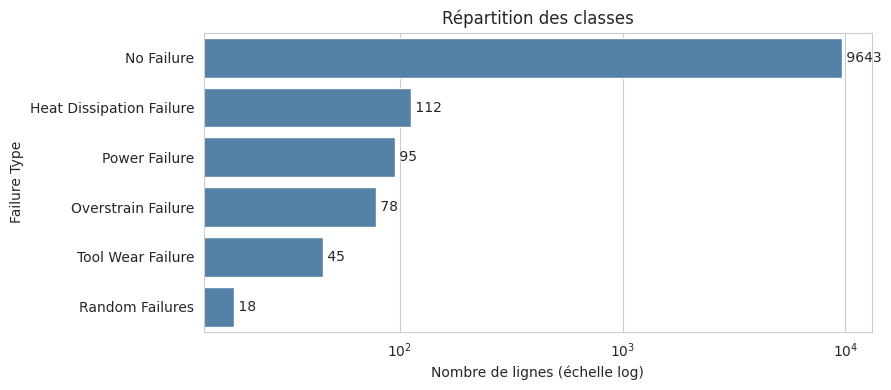

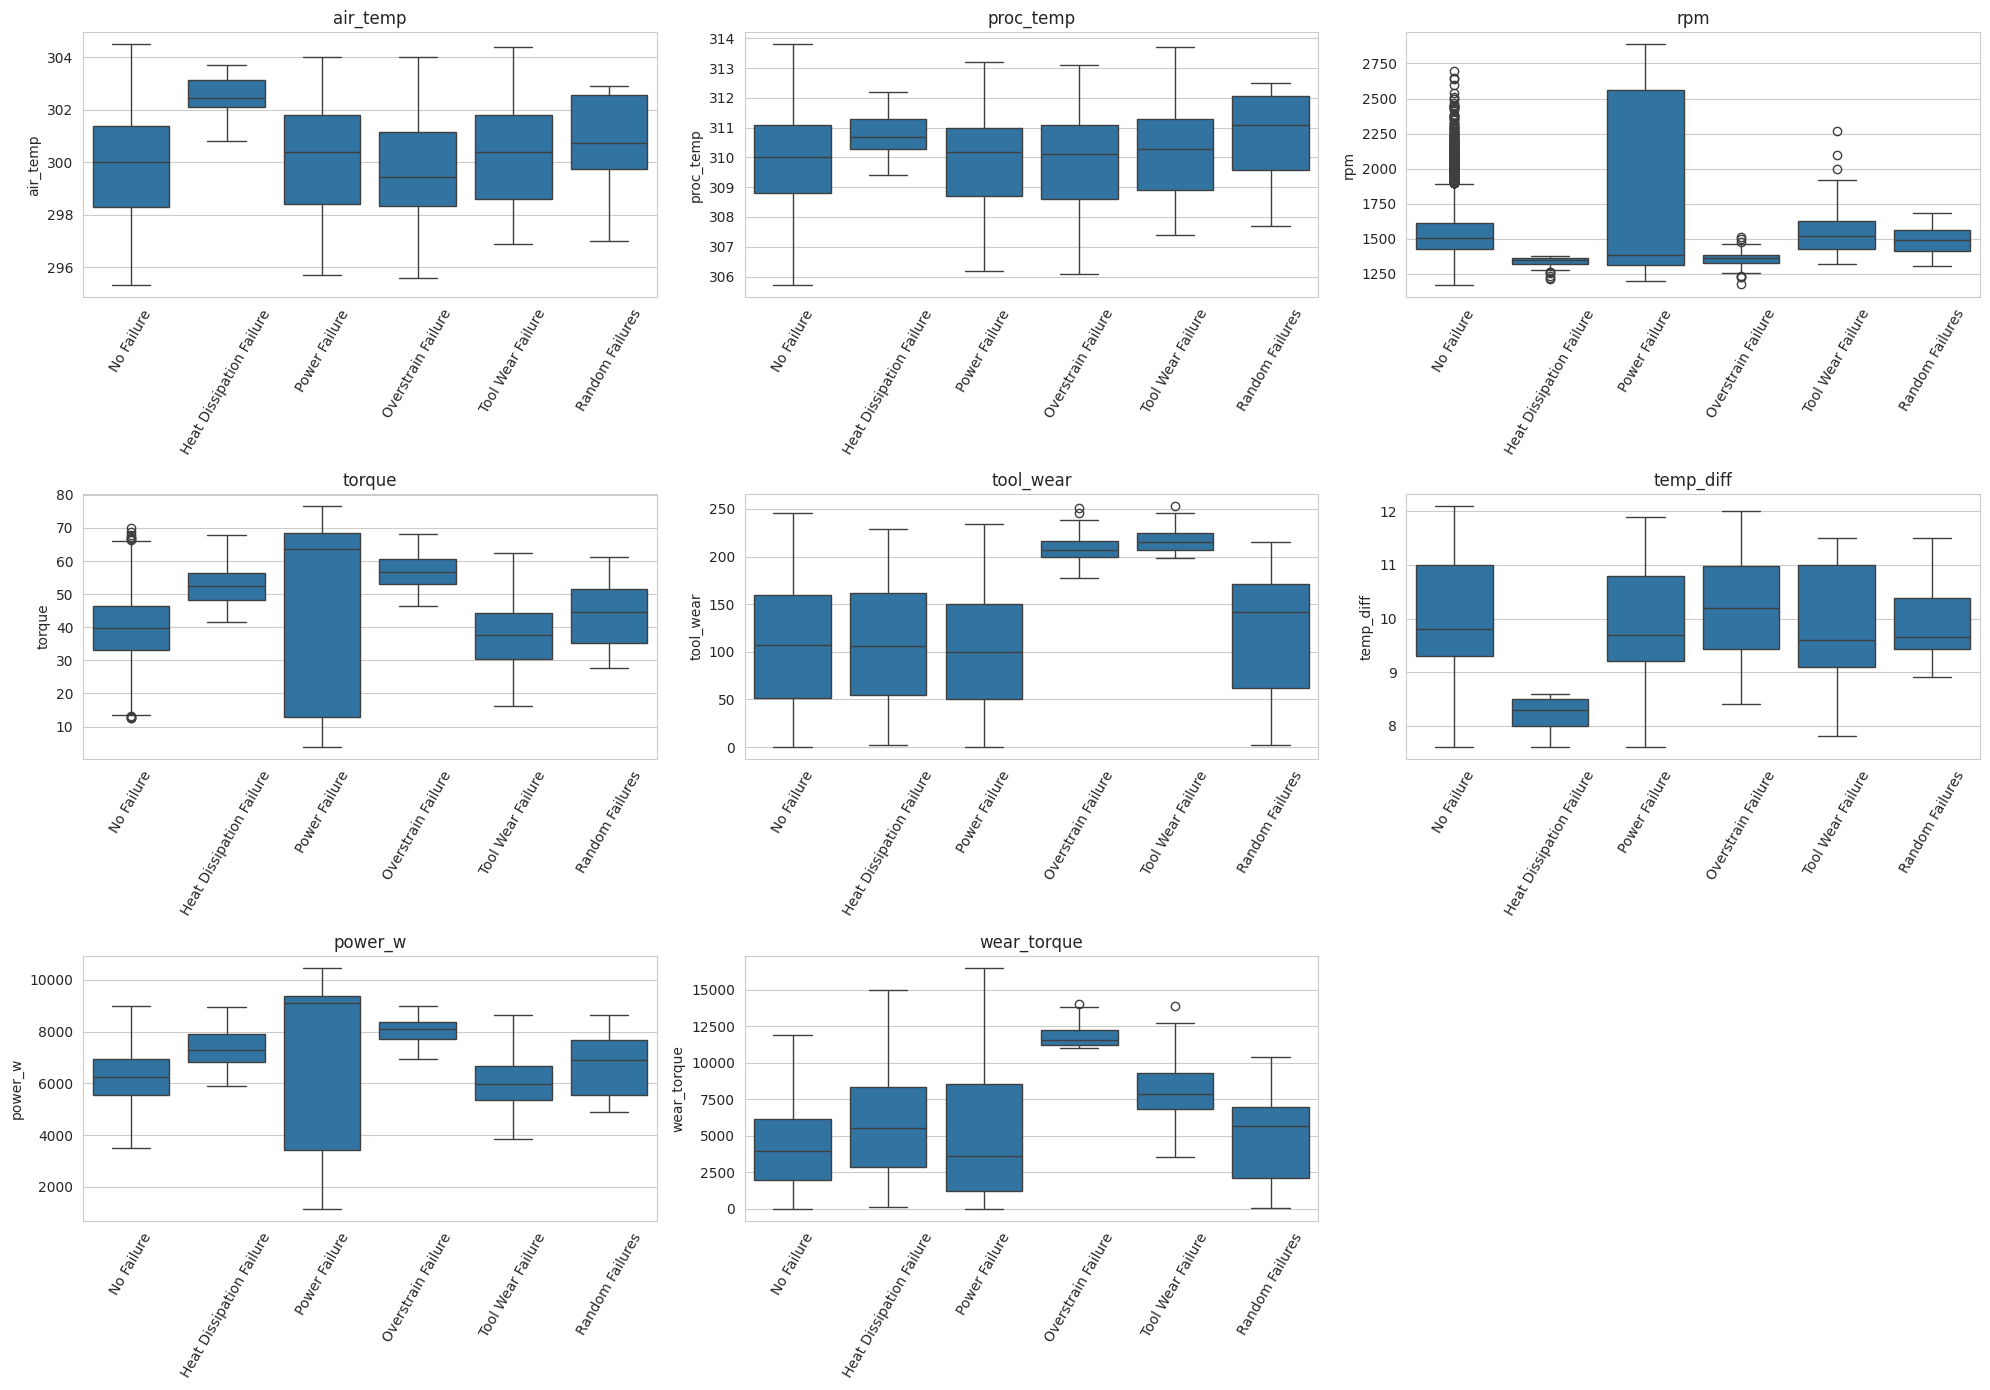

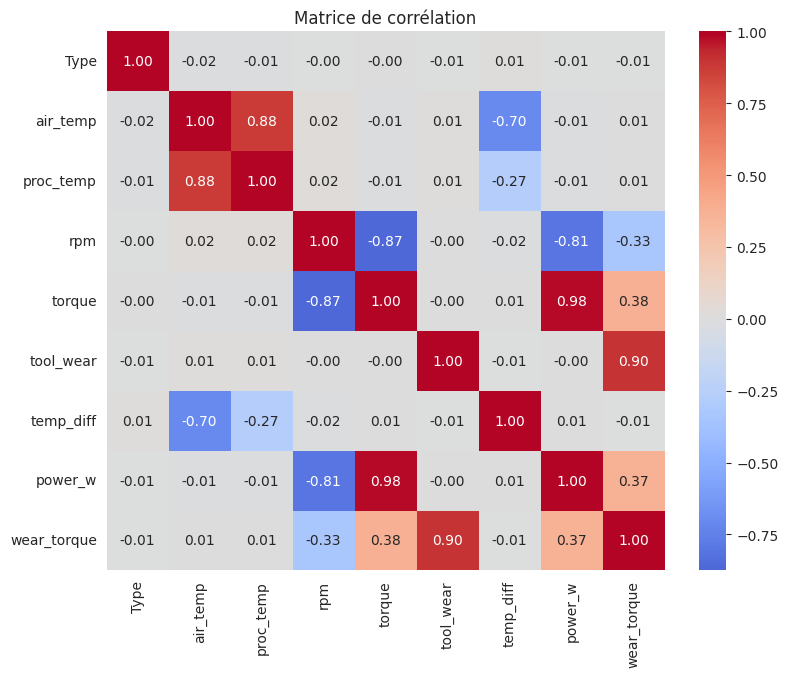

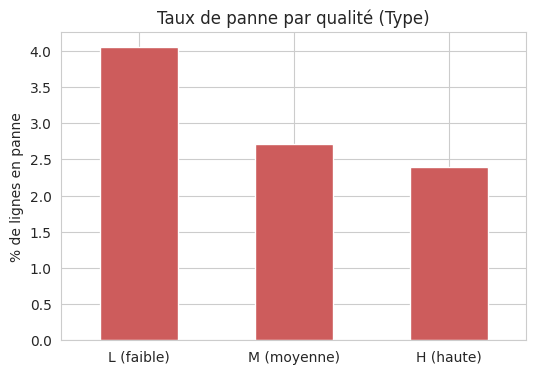

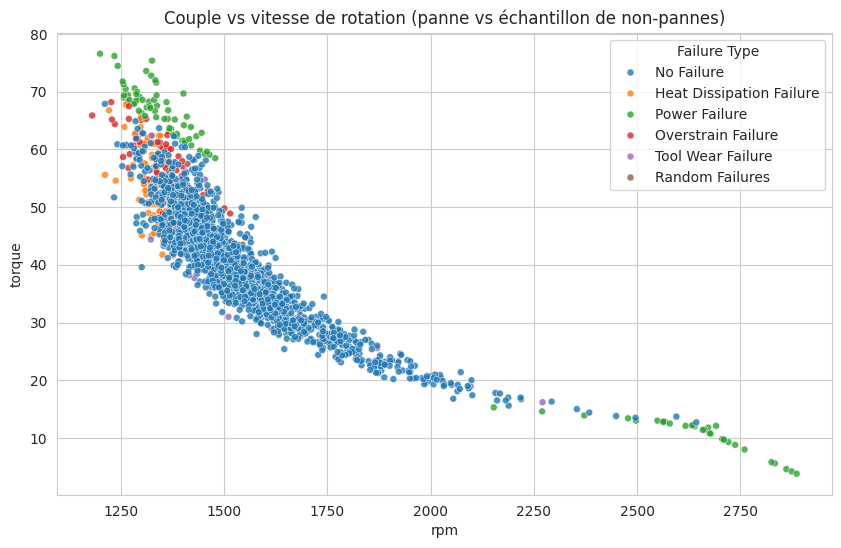

                          air_temp  proc_temp      rpm  torque  tool_wear  \
Failure Type                                                                
Heat Dissipation Failure    302.57     310.80  1337.96   52.78     107.34   
No Failure                  299.97     309.99  1540.35   39.62     106.67   
Overstrain Failure          299.87     310.05  1354.24   56.88     208.22   
Power Failure               300.08     309.95  1763.97   48.51     101.88   
Random Failures             300.77     310.76  1489.44   43.52     119.89   
Tool Wear Failure           300.29     310.16  1570.67   37.23     216.56   

                          temp_diff  power_w  wear_torque  
Failure Type                                               
Heat Dissipation Failure       8.23  7383.50      5670.60  
No Failure                    10.02  6243.74      4212.19  
Overstrain Failure            10.18  8043.05     11794.24  
Power Failure                  9.88  7251.82      5018.71  
Random Failures        

In [24]:
# 1. Déséquilibre des classes
counts = df["Failure Type"].value_counts()
plt.figure(figsize=(9, 4))
sns.barplot(x=counts.values, y=counts.index, color="steelblue")
plt.xscale("log"); plt.xlabel("Nombre de lignes (échelle log)"); plt.title("Répartition des classes")
for i, v in enumerate(counts.values): plt.text(v, i, f" {v}", va="center")
plt.tight_layout(); plt.savefig("images/eda_01_classes.png", dpi=150, bbox_inches="tight"); plt.show()

# 2. Distribution de chaque variable selon la classe
fig, axes = plt.subplots(3, 3, figsize=(20, 14))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="Failure Type", y=col, order=classes, ax=ax)
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=60)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.savefig("images/eda_02_boxplots.png", dpi=150, bbox_inches="tight"); plt.show()

# 3. Corrélations
plt.figure(figsize=(9, 7))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.savefig("images/eda_03_correlation.png", dpi=150, bbox_inches="tight"); plt.show()

# 4. Taux de panne selon la qualité du produit
rate = df.groupby("Type")["y"].apply(lambda s: (s != 0).mean() * 100)
rate.index = ["L (faible)", "M (moyenne)", "H (haute)"]
plt.figure(figsize=(6, 4)); rate.plot(kind="bar", color="indianred")
plt.ylabel("% de lignes en panne"); plt.title("Taux de panne par qualité (Type)"); plt.xticks(rotation=0)
plt.savefig("images/eda_04_taux_panne_type.png", dpi=150, bbox_inches="tight"); plt.show()

# 5. Couple vs vitesse de rotation
samp = pd.concat([df[df["y"] != 0], df[df["y"] == 0].sample(1500, random_state=0)])
plt.figure(figsize=(10, 6))
sns.scatterplot(data=samp, x="rpm", y="torque", hue="Failure Type", hue_order=classes, s=25, alpha=.8)
plt.title("Couple vs vitesse de rotation (panne vs échantillon de non-pannes)")
plt.savefig("images/eda_05_torque_rpm.png", dpi=150, bbox_inches="tight"); plt.show()

# 6. Moyennes par classe
print(df.groupby("Failure Type")[num_cols].mean().round(2))
print("\nTaux de panne par Type (%) :\n", rate.round(2))

Train : 6793 | Validation : 1199 | Test : 1999
No Failure                 avant :  6557 | après :  6557
Heat Dissipation Failure   avant :    76 | après :  6557
Power Failure              avant :    64 | après :  6557
Overstrain Failure         avant :    53 | après :  6557
Tool Wear Failure          avant :    31 | après :  6557
Random Failures            avant :    12 | après :  6557
Test (non modifié) : {'No Failure': np.int64(1929), 'Heat Dissipation Failure': np.int64(22), 'Power Failure': np.int64(19), 'Overstrain Failure': np.int64(16), 'Tool Wear Failure': np.int64(9), 'Random Failures': np.int64(4)}


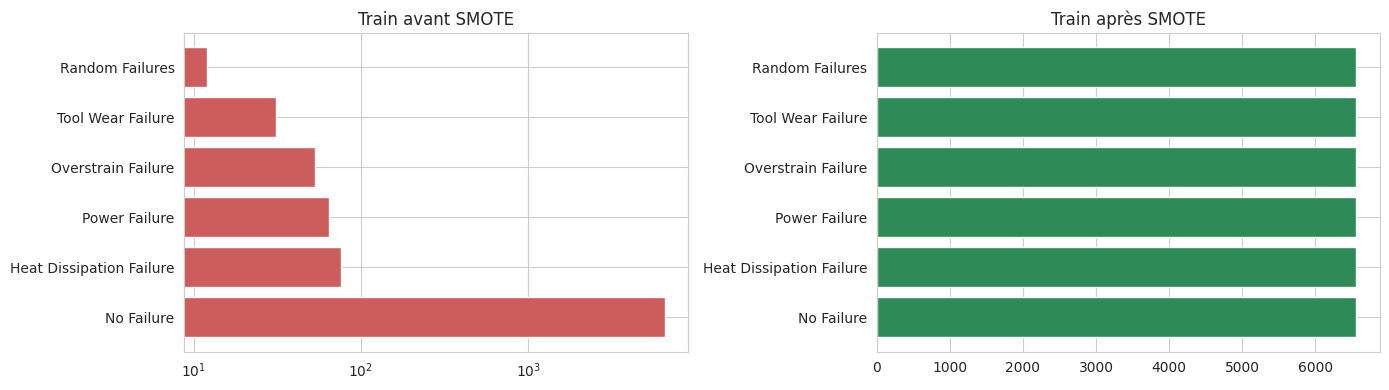

In [25]:
!pip install -q imbalanced-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

X = df[features].values.astype(np.float32)
y = df["y"].values

# Split stratifié : test 20 %, puis validation 15 % du reste
X_trf, X_te, y_trf, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_tr, X_va, y_tr, y_va = train_test_split(X_trf, y_trf, test_size=0.15, stratify=y_trf, random_state=42)
print("Train :", len(X_tr), "| Validation :", len(X_va), "| Test :", len(X_te))

# Normalisation ajustée sur le train uniquement
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_va_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_va), scaler.transform(X_te)

# Augmentation SMOTE sur le train uniquement
before = np.bincount(y_tr, minlength=len(classes))
sm = SMOTE(k_neighbors=3, random_state=42)
X_aug, y_aug = sm.fit_resample(X_tr_s, y_tr)
after = np.bincount(y_aug, minlength=len(classes))
for c, b, a in zip(classes, before, after):
    print(f"{c:<26} avant : {b:>5} | après : {a:>5}")
print("Test (non modifié) :", dict(zip(classes, np.bincount(y_te, minlength=len(classes)))))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].barh(classes, before, color="indianred"); ax[0].set_xscale("log"); ax[0].set_title("Train avant SMOTE")
ax[1].barh(classes, after, color="seagreen"); ax[1].set_title("Train après SMOTE")
plt.tight_layout(); plt.savefig("images/smote_avant_apres.png", dpi=150, bbox_inches="tight"); plt.show()

In [26]:
import copy, torch, torch.nn as nn
from sklearn.metrics import (f1_score, accuracy_score, recall_score, precision_score,
                             classification_report, confusion_matrix)

n_in, n_out = X_tr_s.shape[1], len(classes)
T = lambda a, dt=torch.float32: torch.tensor(a, dtype=dt)
Xaug_t, yaug_t = T(X_aug), T(y_aug, torch.long)
Xtr_t, Xva_t, Xte_t = T(X_tr_s), T(X_va_s), T(X_te_s)
yt_tr, yt_va, yt_te = T(y_tr, torch.long), T(y_va, torch.long), T(y_te, torch.long)
short = ["No F.", "Heat", "Power", "Overstrain", "Tool wear", "Random"]

class MLPC(nn.Module):
    def __init__(self, n_in, n_out, hidden=(64, 32), dropout=0.0, batchnorm=False):
        super().__init__()
        layers, d_in = [], n_in
        for h in hidden:
            layers.append(nn.Linear(d_in, h))
            if batchnorm: layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout > 0: layers.append(nn.Dropout(dropout))
            d_in = h
        layers.append(nn.Linear(d_in, n_out))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

OPTS = {"adam": torch.optim.Adam, "rmsprop": torch.optim.RMSprop,
        "sgd": lambda p, lr, weight_decay: torch.optim.SGD(p, lr=lr, momentum=0.9, weight_decay=weight_decay)}

def eval_set(model, X, yt, yn):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = nn.functional.cross_entropy(logits, yt).item()
        pred = logits.argmax(1).numpy()
    return loss, accuracy_score(yn, pred), f1_score(yn, pred, average="macro", zero_division=0), pred

def train_model(hidden=(64, 32), lr=1e-3, optimizer="adam", epochs=40, batch_size=256,
                weight_decay=0.0, dropout=0.0, batchnorm=False, patience=None, seed=42):
    torch.manual_seed(seed); np.random.seed(seed)
    model = MLPC(n_in, n_out, hidden, dropout, batchnorm)
    opt = OPTS[optimizer](model.parameters(), lr=lr, weight_decay=weight_decay)
    sets = {"tr": (Xtr_t, yt_tr, y_tr), "va": (Xva_t, yt_va, y_va), "te": (Xte_t, yt_te, y_te)}
    hist = {f"{s}_{k}": [] for s in sets for k in ["loss", "acc", "f1"]}
    best, best_state, best_ep, wait = -1.0, None, 0, 0
    n = len(Xaug_t)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            if len(idx) < 2: continue
            opt.zero_grad()
            loss = nn.functional.cross_entropy(model(Xaug_t[idx]), yaug_t[idx])
            loss.backward(); opt.step()
        for s, (X_, yt_, yn_) in sets.items():
            l, a, f, _ = eval_set(model, X_, yt_, yn_)
            hist[f"{s}_loss"].append(l); hist[f"{s}_acc"].append(a); hist[f"{s}_f1"].append(f)
        if hist["va_f1"][-1] > best + 1e-6:          # sélection sur la validation (F1 macro)
            best, best_ep, wait = hist["va_f1"][-1], ep + 1, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
        if patience and wait >= patience:
            print(f"Early stopping à l'epoch {ep + 1} (meilleure epoch : {best_ep})")
            break
    if patience and best_state is not None:
        model.load_state_dict(best_state)
    hist["best_ep"] = best_ep
    return model, hist

def plot_history(h, title, path=None):
    ep = range(1, len(h["tr_loss"]) + 1)
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
    for a, (k, name) in zip(ax, [("loss", "Loss (cross-entropy)"), ("acc", "Accuracy"), ("f1", "F1 macro")]):
        a.plot(ep, h[f"tr_{k}"], label="Train (réel)")
        a.plot(ep, h[f"va_{k}"], "--", label="Validation")
        a.plot(ep, h[f"te_{k}"], label="Test")
        a.set_xlabel("Epochs"); a.set_ylabel(name); a.set_title(f"{name} / Epochs"); a.legend()
    fig.suptitle(title); plt.tight_layout()
    if path: plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

def full_report(model, name, path=None):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for ax, (split, X_, yt_, yn_) in zip(axes, [("TRAIN (réel, sans SMOTE)", Xtr_t, yt_tr, y_tr),
                                                ("TEST", Xte_t, yt_te, y_te)]):
        _, acc, f1m, pred = eval_set(model, X_, yt_, yn_)
        print(f"\n===== {name} | {split} =====")
        print(f"Accuracy = {acc:.4f} | Sensibilité (recall macro) = {recall_score(yn_, pred, average='macro', zero_division=0):.4f}"
              f" | Précision macro = {precision_score(yn_, pred, average='macro', zero_division=0):.4f}"
              f" | F1 macro = {f1m:.4f} | F1 pondéré = {f1_score(yn_, pred, average='weighted', zero_division=0):.4f}")
        print(classification_report(yn_, pred, target_names=classes, labels=range(len(classes)), zero_division=0, digits=3))
        cm = confusion_matrix(yn_, pred, labels=range(len(classes)))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=short, yticklabels=short, ax=ax)
        ax.set_title(f"Matrice de confusion : {split}"); ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")
    plt.tight_layout()
    if path: plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

print("Référence : toujours prédire 'No Failure' donne une accuracy test de", round((y_te == 0).mean(), 4))

Référence : toujours prédire 'No Failure' donne une accuracy test de 0.965


In [27]:
!pip install -q skorch
from skorch import NeuralNetClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import GridSearchCV, StratifiedKFold

def to32(X): return np.asarray(X, dtype=np.float32)

pipe = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(k_neighbors=3, random_state=42)),
    ("to32", FunctionTransformer(to32)),
    ("net", NeuralNetClassifier(MLPC, module__n_in=n_in, module__n_out=n_out,
                                criterion=nn.CrossEntropyLoss, optimizer=torch.optim.Adam,
                                max_epochs=20, batch_size=256, lr=1e-3,
                                train_split=None, verbose=0)),
])

param_grid = {
    "net__lr": [1e-3, 1e-2],
    "net__optimizer": [torch.optim.Adam, torch.optim.RMSprop],
    "net__max_epochs": [20, 40],
    "net__module__hidden": [(32,), (64, 32), (128, 64, 32)],
}

gs = GridSearchCV(pipe, param_grid, cv=StratifiedKFold(3, shuffle=True, random_state=42),
                  scoring="f1_macro", refit=False, n_jobs=1, verbose=1)
gs.fit(X_tr, y_tr)

print("\nMeilleurs hyperparamètres :", gs.best_params_)
print("Meilleur F1 macro (validation croisée) :", round(gs.best_score_, 4))
res = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")
print(res[["params", "mean_test_score", "std_test_score"]].head(5).to_string())

Fitting 3 folds for each of 24 candidates, totalling 72 fits

Meilleurs hyperparamètres : {'net__lr': 0.001, 'net__max_epochs': 40, 'net__module__hidden': (128, 64, 32), 'net__optimizer': <class 'torch.optim.adam.Adam'>}
Meilleur F1 macro (validation croisée) : 0.3326
                                                                                                                                 params  mean_test_score  std_test_score
10   {'net__lr': 0.001, 'net__max_epochs': 40, 'net__module__hidden': (128, 64, 32), 'net__optimizer': <class 'torch.optim.adam.Adam'>}         0.332638        0.015726
8         {'net__lr': 0.001, 'net__max_epochs': 40, 'net__module__hidden': (64, 32), 'net__optimizer': <class 'torch.optim.adam.Adam'>}         0.322412        0.021252
7      {'net__lr': 0.001, 'net__max_epochs': 40, 'net__module__hidden': (32,), 'net__optimizer': <class 'torch.optim.rmsprop.RMSprop'>}         0.320953        0.029573
19      {'net__lr': 0.01, 'net__max_epochs': 40, 'net__

Config modèle 1 : {'hidden': (128, 64, 32), 'lr': 0.001, 'optimizer': 'adam', 'epochs': 40, 'batch_size': 256}


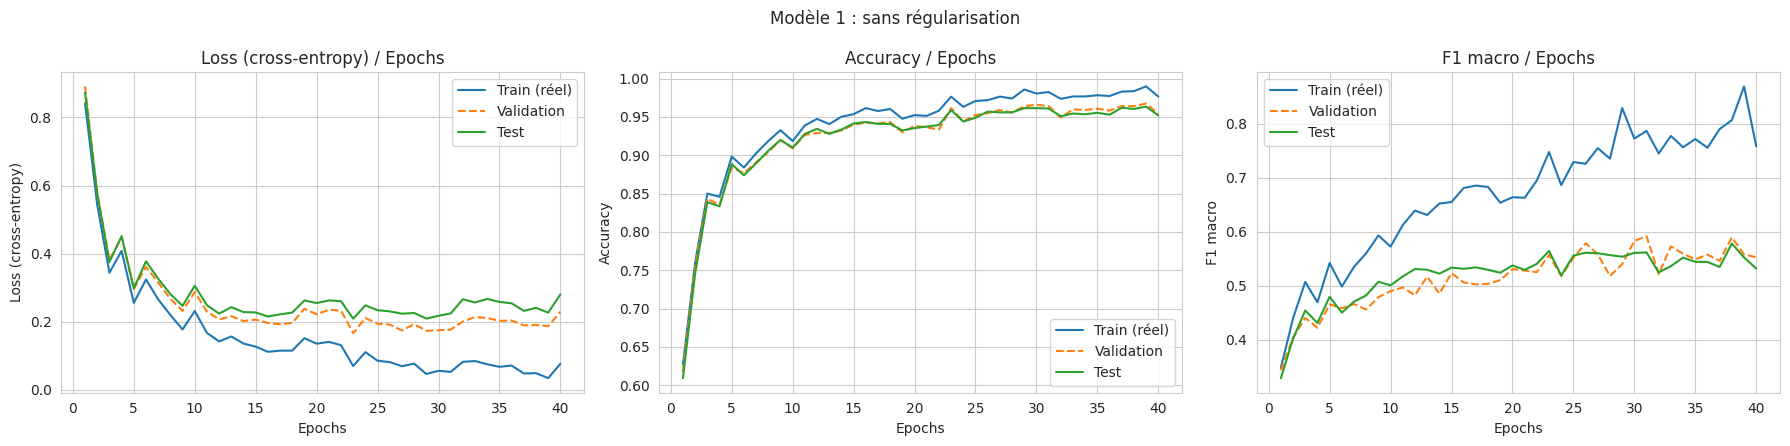


===== Modèle 1 | TRAIN (réel, sans SMOTE) =====
Accuracy = 0.9766 | Sensibilité (recall macro) = 0.9960 | Précision macro = 0.6594 | F1 macro = 0.7581 | F1 pondéré = 0.9812
                          precision    recall  f1-score   support

              No Failure      1.000     0.976     0.988      6557
Heat Dissipation Failure      0.776     1.000     0.874        76
           Power Failure      0.928     1.000     0.962        64
      Overstrain Failure      0.624     1.000     0.768        53
       Tool Wear Failure      0.287     1.000     0.446        31
         Random Failures      0.343     1.000     0.511        12

                accuracy                          0.977      6793
               macro avg      0.659     0.996     0.758      6793
            weighted avg      0.989     0.977     0.981      6793


===== Modèle 1 | TEST =====
Accuracy = 0.9520 | Sensibilité (recall macro) = 0.6559 | Précision macro = 0.4665 | F1 macro = 0.5315 | F1 pondéré = 0.9616
         

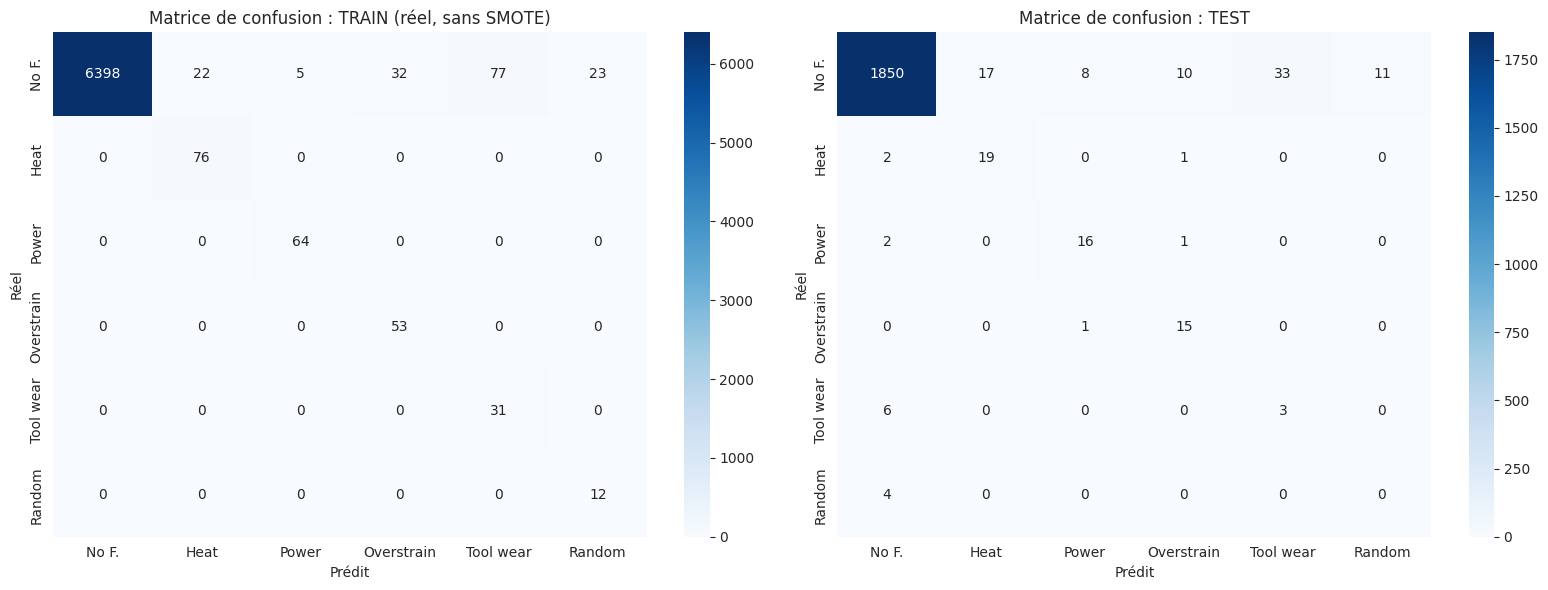

Epoch avec le meilleur F1 macro de validation : 31


In [28]:
b = gs.best_params_
cfg = dict(hidden=b["net__module__hidden"], lr=b["net__lr"],
           optimizer=b["net__optimizer"].__name__.lower(),
           epochs=b["net__max_epochs"], batch_size=256)
print("Config modèle 1 :", cfg)

model1, hist1 = train_model(**cfg)
plot_history(hist1, "Modèle 1 : sans régularisation", "images/modele1_courbes.png")
full_report(model1, "Modèle 1", "images/modele1_confusion.png")
print("Epoch avec le meilleur F1 macro de validation :", hist1["best_ep"])


--- 1. Baseline (sans régularisation) ---

--- 2. + Dropout (0.3) ---

--- 3. + L2 (weight decay 1e-3) ---

--- 4. + BatchNorm ---

--- 5. + Early stopping (patience 8) ---
Early stopping à l'epoch 39 (meilleure epoch : 31)
Early stopping à l'epoch 34 (meilleure epoch : 26)
Early stopping à l'epoch 35 (meilleure epoch : 27)

--- 6. Toutes combinées ---
Early stopping à l'epoch 30 (meilleure epoch : 22)
Early stopping à l'epoch 33 (meilleure epoch : 25)

=== COMPARAISON (moyenne sur 3 seeds) ===
                           Modèle  Accuracy test  Sensibilité macro test  F1 macro train  F1 macro val  F1 macro test  ± F1 test
1. Baseline (sans régularisation)         0.9615                  0.6306          0.8144        0.5661         0.5584     0.0240
               2. + Dropout (0.3)         0.9200                  0.7314          0.5988        0.4881         0.5116     0.0116
      3. + L2 (weight decay 1e-3)         0.9220                  0.6612          0.6125        0.4982         0

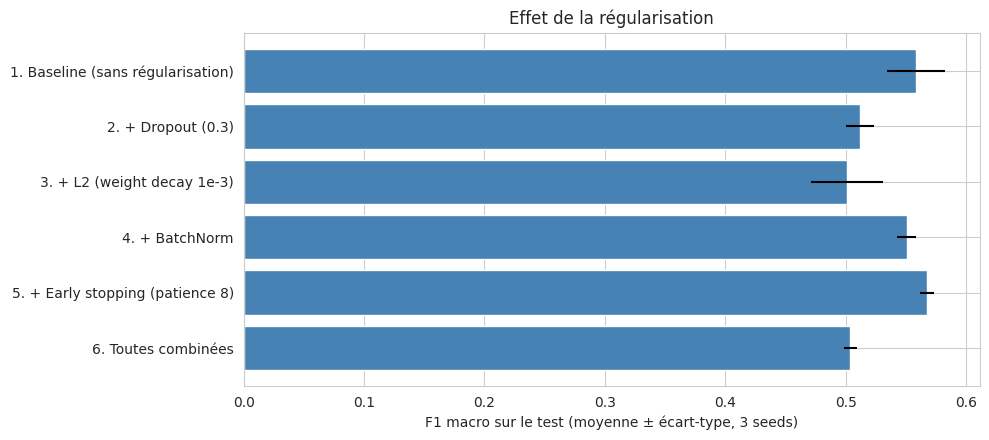

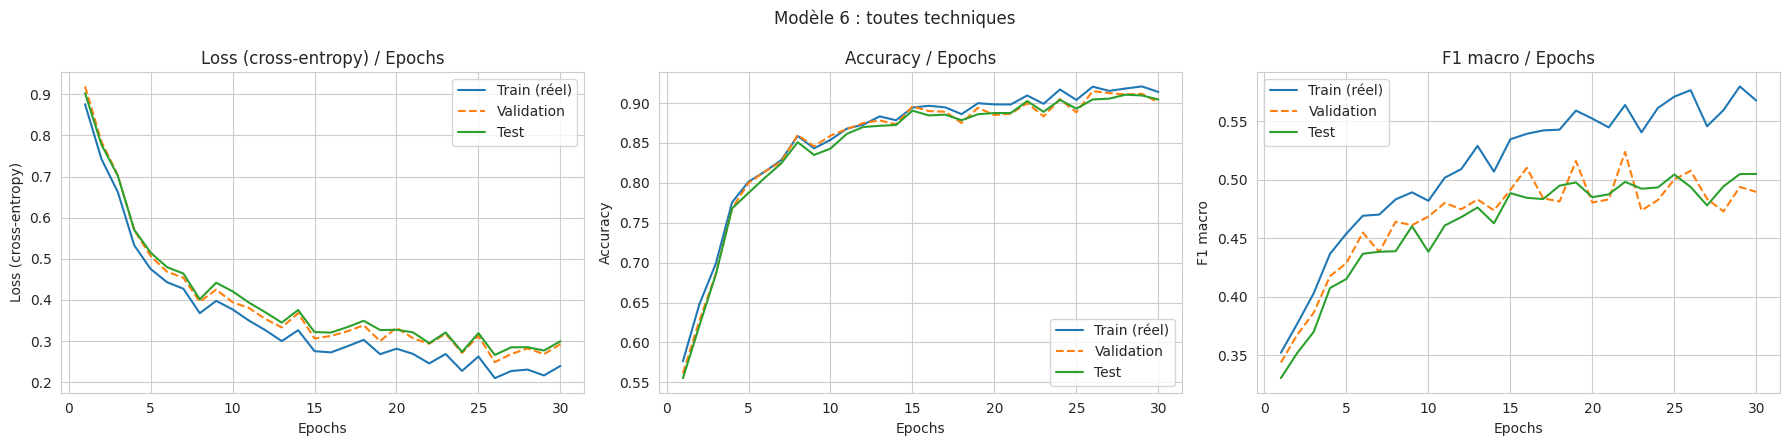

Meilleur modèle selon la validation : 5. + Early stopping (patience 8)

===== 5. + Early stopping (patience 8) | TRAIN (réel, sans SMOTE) =====
Accuracy = 0.9825 | Sensibilité (recall macro) = 0.9970 | Précision macro = 0.6990 | F1 macro = 0.7868 | F1 pondéré = 0.9857
                          precision    recall  f1-score   support

              No Failure      1.000     0.982     0.991      6557
Heat Dissipation Failure      0.826     1.000     0.905        76
           Power Failure      0.914     1.000     0.955        64
      Overstrain Failure      0.803     1.000     0.891        53
       Tool Wear Failure      0.365     1.000     0.534        31
         Random Failures      0.286     1.000     0.444        12

                accuracy                          0.982      6793
               macro avg      0.699     0.997     0.787      6793
            weighted avg      0.992     0.982     0.986      6793


===== 5. + Early stopping (patience 8) | TEST =====
Accuracy = 0.96

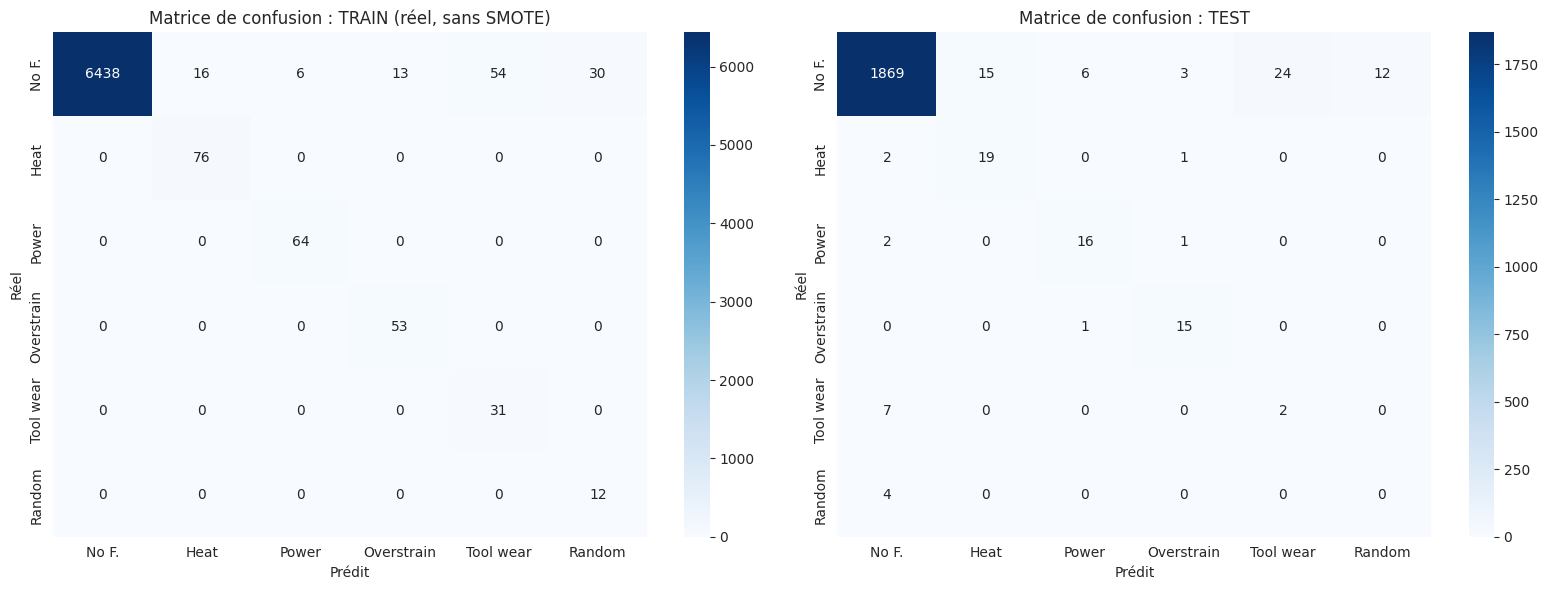

In [29]:
configs = {
    "1. Baseline (sans régularisation)": {},
    "2. + Dropout (0.3)": dict(dropout=0.3),
    "3. + L2 (weight decay 1e-3)": dict(weight_decay=1e-3),
    "4. + BatchNorm": dict(batchnorm=True),
    "5. + Early stopping (patience 8)": dict(patience=8),
    "6. Toutes combinées": dict(dropout=0.3, weight_decay=1e-3, batchnorm=True, patience=8),
}
seeds = [42, 1, 2]
rows, hists_reg, models_reg = [], {}, {}

for name, extra in configs.items():
    print(f"\n--- {name} ---")
    acc_te, f1_te, rec_te, f1_va, f1_tr = [], [], [], [], []
    for sd in seeds:
        m, h = train_model(**{**cfg, **extra, "seed": sd})
        if sd == seeds[0]:
            hists_reg[name], models_reg[name] = h, m
        _, a_te, f_te, p_te = eval_set(m, Xte_t, yt_te, y_te)
        _, _, f_va, _ = eval_set(m, Xva_t, yt_va, y_va)
        _, _, f_tr, _ = eval_set(m, Xtr_t, yt_tr, y_tr)
        acc_te.append(a_te); f1_te.append(f_te); f1_va.append(f_va); f1_tr.append(f_tr)
        rec_te.append(recall_score(y_te, p_te, average="macro", zero_division=0))
    rows.append({"Modèle": name,
                 "Accuracy test": np.mean(acc_te), "Sensibilité macro test": np.mean(rec_te),
                 "F1 macro train": np.mean(f1_tr), "F1 macro val": np.mean(f1_va),
                 "F1 macro test": np.mean(f1_te), "± F1 test": np.std(f1_te)})

results = pd.DataFrame(rows)
print("\n=== COMPARAISON (moyenne sur 3 seeds) ===")
print(results.round(4).to_string(index=False))
results.to_csv("results.csv", index=False)

plt.figure(figsize=(10, 4.5))
plt.barh(results["Modèle"], results["F1 macro test"], xerr=results["± F1 test"], color="steelblue")
plt.gca().invert_yaxis(); plt.xlabel("F1 macro sur le test (moyenne ± écart-type, 3 seeds)")
plt.title("Effet de la régularisation")
plt.tight_layout(); plt.savefig("images/comparaison_regularisation.png", dpi=150, bbox_inches="tight"); plt.show()

plot_history(hists_reg["6. Toutes combinées"], "Modèle 6 : toutes techniques", "images/modele6_courbes.png")

best_name = results.loc[results["F1 macro val"].idxmax(), "Modèle"]   # choix sur la validation
print("Meilleur modèle selon la validation :", best_name)
full_report(models_reg[best_name], best_name, "images/meilleur_modele_confusion.png")

In [31]:
!zip -qr images.zip images
from google.colab import files
files.download("images.zip")
files.download("results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>